# One-day risk for a stock and a portfolio

How does downside risk change when a $10,000 investment in Apple is spread across several stocks? Start with Apple alone, add Microsoft, then compare two ways of weighting a five-stock portfolio. Each example measures one-day 95% value at risk and expected shortfall.

## 1. Univariate model for Apple

The bundled CSV contains Yahoo Finance’s daily adjusted closing prices in USD for January–December 2024. Adjusted closes account for splits and dividends. Taking differences of log prices gives one return per pair of consecutive trading sessions. Use their sample mean and sample standard deviation as the model inputs. [Yahoo Finance data snapshot source](https://query1.finance.yahoo.com/v8/finance/chart/AAPL?period1=1704067200&period2=1735689600&interval=1d)

In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

with Path("data/aapl_2024_adjusted_close.csv").open(newline="") as file:
    rows = list(csv.DictReader(file))

prices = np.array([float(row["adjusted_close_usd"]) for row in rows])
log_returns = np.diff(np.log(prices))
daily_mean = log_returns.mean()
daily_volatility = log_returns.std(ddof=1)

print(f"{len(prices)} closes, {rows[0]['date']} through {rows[-1]['date']}")
print(f"{len(log_returns)} daily log returns")
print(f"Daily mean {daily_mean:.4%} | Daily volatility {daily_volatility:.4%}")

252 closes, 2024-01-02 through 2024-12-31
251 daily log returns
Daily mean 0.1212% | Daily volatility 1.4063%


## 2. Simulate returns and measure losses

Draw one-day log returns $r$ from a normal distribution with the fitted mean and volatility. For an initial position of $V$ dollars, the simulated dollar loss is $L = V(1-e^r)$. Negative losses represent gains.

- **VaR** is the 95th percentile of the simulated losses. About 5% of scenarios exceed that dollar threshold.
- **Expected shortfall** is the average loss across those worst 5% of scenarios.

In [2]:
position_usd = 10_000
confidence = 0.95
scenario_count = 100_000
seed = 42

rng = np.random.default_rng(seed)
simulated_returns = rng.normal(daily_mean, daily_volatility, scenario_count)
losses = -position_usd * np.expm1(simulated_returns)

value_at_risk = np.quantile(losses, confidence)
tail_count = round(scenario_count * (1 - confidence))
expected_shortfall = np.sort(losses)[-tail_count:].mean()

print(f"95% one-day VaR   ${value_at_risk:,.2f} ({value_at_risk / position_usd:.2%} of position)")
print(f"95% one-day ES    ${expected_shortfall:,.2f} ({expected_shortfall / position_usd:.2%} of position)")
print(f"About 1 in 20 simulated days lost more than ${value_at_risk:,.2f}.")
print(f"The worst {tail_count:,} scenarios averaged a loss of ${expected_shortfall:,.2f}.")

95% one-day VaR   $218.66 (2.19% of position)
95% one-day ES    $275.47 (2.75% of position)
About 1 in 20 simulated days lost more than $218.66.
The worst 5,000 scenarios averaged a loss of $275.47.


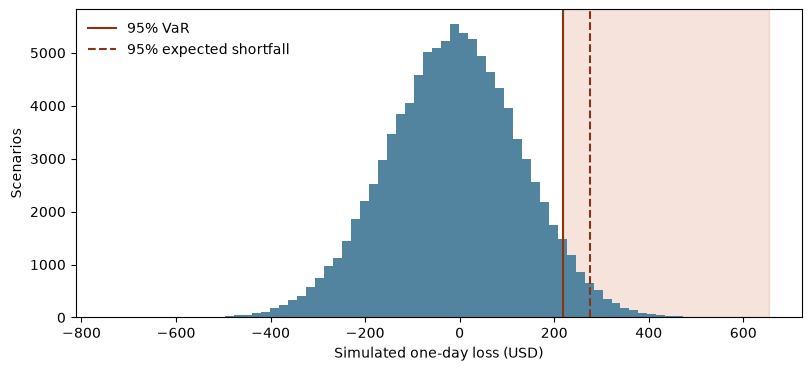

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
ax.hist(losses, bins=70, color="#52849f")
ax.axvspan(value_at_risk, ax.get_xlim()[1], color="#c86540", alpha=0.18, zorder=0)
ax.axvline(value_at_risk, color="#873415", label="95% VaR")
ax.axvline(expected_shortfall, color="#873415", linestyle="--", label="95% expected shortfall")
ax.set(xlabel="Simulated one-day loss (USD)", ylabel="Scenarios")
ax.legend(frameon=False)
plt.show()

## 3. Check the simulation

The fitted normal-return model also gives a closed-form VaR and ES. Comparing against these values checks the simulation under the same assumptions.

In [4]:
from math import exp, expm1
from statistics import NormalDist

normal = NormalDist()
tail_probability = 1 - confidence
z = normal.inv_cdf(tail_probability)
analytic_var = -position_usd * expm1(daily_mean + daily_volatility * z)
tail_value_ratio = (
    exp(daily_mean + daily_volatility**2 / 2)
    * normal.cdf(z - daily_volatility)
    / tail_probability
)
analytic_es = position_usd * (1 - tail_value_ratio)

print(f"Closed-form VaR   ${analytic_var:,.2f}")
print(f"Closed-form ES    ${analytic_es:,.2f}")

Closed-form VaR   $216.81
Closed-form ES    $273.99


The simulated values are within $2 of the model’s closed-form values. VaR locates the start of the loss tail, while expected shortfall tells us how costly that tail is on average. The model uses one year of prices and assumes normally distributed log returns with constant volatility, so it can understate losses if extreme moves occur more frequently than the model assumes.

## 4. Portfolio model for Apple and Microsoft

Start with $5,000 in each stock and hold both positions for one trading day. Pair adjusted closing prices by trading date and estimate the covariance matrix of their daily log returns. Its diagonal records each stock’s variance, and its off-diagonal records how their returns move together. [Microsoft prices from Yahoo Finance](https://query1.finance.yahoo.com/v8/finance/chart/MSFT?period1=1704067200&period2=1735689600&interval=1d)

In [5]:
with Path("data/msft_2024_adjusted_close.csv").open(newline="") as file:
    msft_by_date = {row["date"]: float(row["adjusted_close_usd"]) for row in csv.DictReader(file)}

# Both snapshots cover the same trading sessions in ascending order.
dates = [row["date"] for row in rows]
assert dates == sorted(msft_by_date)
paired_prices = np.column_stack([prices, [msft_by_date[date] for date in dates]])
paired_returns = np.diff(np.log(paired_prices), axis=0)
mean_returns = paired_returns.mean(axis=0)
covariance = np.cov(paired_returns, rowvar=False)
correlation = np.corrcoef(paired_returns, rowvar=False)[0, 1]
print(f"Historical daily return correlation: {correlation:.2f}")

Historical daily return correlation: 0.47


Each draw from the fitted multivariate normal distribution gives **one possible day for both stocks**. Convert each stock’s log return into a dollar gain or loss, add the two losses for that day, then measure the tail of the resulting portfolio losses.

In [6]:
weights = np.array([0.5, 0.5])  # AAPL, MSFT
portfolio_rng = np.random.default_rng(seed)
joint_returns = portfolio_rng.multivariate_normal(mean_returns, covariance, size=scenario_count)
portfolio_losses = -np.expm1(joint_returns) @ (position_usd * weights)
portfolio_var = np.quantile(portfolio_losses, confidence)
portfolio_es = np.sort(portfolio_losses)[-tail_count:].mean()

print(f"{'Position':<22} {'95% VaR':>10} {'95% ES':>10}")
for label, var, es in [("Apple only", value_at_risk, expected_shortfall),
                       ("50/50 Apple–Microsoft", portfolio_var, portfolio_es)]:
    print(f"{label:<22} ${var:>9.2f} ${es:>9.2f}")

Position                  95% VaR     95% ES
Apple only             $   218.66 $   275.47
50/50 Apple–Microsoft  $   178.77 $   225.52


The fitted correlation of 0.47 means the stocks tended to move in the same direction, with room for one stock’s gain to offset some of the other’s loss. Splitting the position lowered both tail estimates in this simulation. The amount depends on each stock’s volatility and their correlation. If they fall together more often in a future downturn, losses can exceed what this model suggests.

## 5. Diversification across five stocks

Add JPMorgan Chase (JPM), Exxon Mobil (XOM), and Johnson & Johnson (JNJ) to Apple and Microsoft. These holdings introduce finance, energy, and health care exposure. Compare two rules: put 20% in each stock, or choose weights that minimize the estimated variance of the portfolio’s daily simple return. The second rule gives more weight to stocks that help offset fluctuations elsewhere in the portfolio.

Estimate both rules’ risk on the same 100,000 simulated days, with the full $10,000 invested and positions held for one day.

In [7]:
tickers = ["AAPL", "MSFT", "JPM", "XOM", "JNJ"]
price_columns = []
for ticker in tickers:
    with Path(f"data/{ticker.lower()}_2024_adjusted_close.csv").open(newline="") as file:
        observations = list(csv.DictReader(file))
    assert [row["date"] for row in observations] == dates
    price_columns.append([float(row["adjusted_close_usd"]) for row in observations])

stock_returns = np.diff(np.log(np.column_stack(price_columns)), axis=0)
simple_cov = np.cov(np.expm1(stock_returns), rowvar=False)
# Fully invested minimum-variance weights are proportional to inverse covariance times ones.
raw_weights = np.linalg.solve(simple_cov, np.ones(len(tickers)))
min_var_weights = raw_weights / raw_weights.sum()
assert np.all(min_var_weights >= 0)  # The fitted solution holds no short positions.
equal_weights = np.full(len(tickers), 1 / len(tickers))
print("Minimum-variance allocation")
for ticker, weight in zip(tickers, min_var_weights):
    print(f"{ticker:5} {weight:6.1%}")

Minimum-variance allocation
AAPL   11.1%
MSFT   22.4%
JPM     3.6%
XOM    22.7%
JNJ    40.3%


In [8]:
joint_draws = np.random.default_rng(seed).multivariate_normal(
    stock_returns.mean(axis=0), np.cov(stock_returns, rowvar=False), size=scenario_count
)
stock_losses = -position_usd * np.expm1(joint_draws)
allocations = dict(zip(tickers, np.eye(len(tickers))))
allocations["Apple–Microsoft 50/50"] = [0.5, 0.5, 0, 0, 0]
allocations["Five stocks, equal"] = equal_weights
allocations["Five stocks, min variance"] = min_var_weights
print(f"{'Position':<26} {'95% VaR ($)':>12} {'95% ES ($)':>12}")
for label, allocation in allocations.items():
    scenario_losses = stock_losses @ allocation
    var = np.quantile(scenario_losses, confidence)
    es = np.sort(scenario_losses)[-tail_count:].mean()
    print(f"{label:<26} {var:>12.2f} {es:>12.2f}")

Position                    95% VaR ($)   95% ES ($)
AAPL                             216.48       273.28
MSFT                             199.68       251.04
JPM                              226.38       286.19
XOM                              193.47       243.09


JNJ                              156.42       195.44
Apple–Microsoft 50/50            176.97       223.58
Five stocks, equal               105.54       133.67
Five stocks, min variance         98.80       124.10


Both five-stock portfolios had lower VaR and expected shortfall than any single stock in this simulation. Most of the reduction came from spreading the investment across stocks whose returns moved differently. Adjusting the weights reduced the average loss on the worst 5% of days a further $9.57 relative to equal weights.

The weights and simulated returns both use the 2024 sample. This comparison illustrates diversification under the fitted model. Future volatility and correlations can change.